# Chapter 12 — The IMU

Companion notebook to **Chapter 12**. The measurement model, the Allan deviation, strapdown drift, preintegration and
its covariance, the bias Jacobians, and the IMU factor — each checked numerically.

In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd().parent            # the code/ directory
sys.path[:0] = [str(ROOT), str(ROOT / "examples")]

import numpy as np
import matplotlib.pyplot as plt
from vslam import imu
from vslam.lie import so3_exp, so3_log

np.set_printoptions(precision=4, suppress=True)
rng = np.random.default_rng(0)
P = imu.ImuParams()
# after the imports: the example scripts select the Agg backend
%matplotlib inline

## 1. Specific force (Definition 12.1)

An accelerometer at rest reads $+9.81$ m/s² *upwards*; tilted, it reads the vertical in body coordinates.

In [2]:
R = imu.euler_zyx(np.radians(30.0), np.radians(-5.0), np.radians(10.0))   # yaw, pitch, roll
print("level IMU at rest:", np.eye(3).T @ (np.zeros(3) - imu.GRAVITY))
f = R.T @ (np.zeros(3) - imu.GRAVITY)
print("tilted IMU at rest:", f)
roll, pitch = np.degrees(np.arctan2(f[1], f[2])), np.degrees(np.arcsin(-f[0] / np.linalg.norm(f)))
print(f"roll {roll:.2f} deg, pitch {pitch:.2f} deg (yaw is not observable, Exercise 12.3)")

level IMU at rest: [0.   0.   9.81]
tilted IMU at rest: [0.855  1.697  9.6242]
roll 10.00 deg, pitch -5.00 deg (yaw is not observable, Exercise 12.3)


## 2. Discrete noise and the Allan deviation (Propositions 12.2 and 12.4)

per-sample gyro noise at 200 Hz: 2.40e-03 rad/s = 0.137 deg/s
minimum at tau* = 15.2 s, sigma_A = 6.16e-05 rad/s (Exercise 12.1)


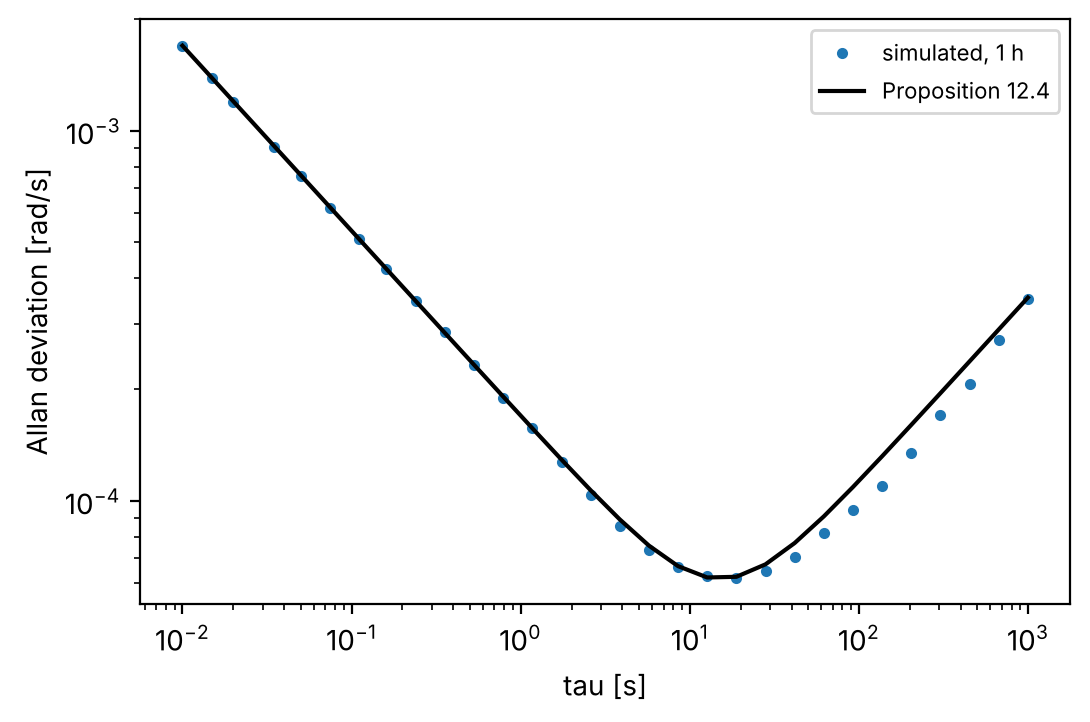

In [3]:
sg, sa, sbg, sba = P.discrete()
print(f"per-sample gyro noise at {P.rate:.0f} Hz: {sg:.2e} rad/s = {np.degrees(sg):.3f} deg/s")
n = int(1 * 3600 * P.rate)                         # one hour, gyro x only
gyro = np.cumsum(rng.normal(0, sbg, n)) + rng.normal(0, sg, n)
t, a = imu.allan_deviation(gyro, P.dt, np.logspace(-2, 3, 30))
plt.figure(figsize=(6, 3.8))
plt.loglog(t, a, "o", ms=3, label="simulated, 1 h")
plt.loglog(t, np.sqrt(P.sigma_g**2 / t + P.sigma_bg**2 * t / 3), "k-", label="Proposition 12.4")
plt.xlabel("tau [s]"); plt.ylabel("Allan deviation [rad/s]"); plt.legend(fontsize=8)
tau_star = np.sqrt(3) * P.sigma_g / P.sigma_bg
print(f"minimum at tau* = {tau_star:.1f} s, sigma_A = {P.sigma_g * np.sqrt(2 / tau_star):.2e} rad/s (Exercise 12.1)")

## 3. Strapdown drift (Proposition 12.6)

A level IMU at rest, biases known: only the white noise integrates.

In [4]:
from ch12_imu import drift_mc, drift_theory
t, mc = drift_mc(np.random.default_rng(1), T=20.0, runs=100)
sd, _, _ = drift_theory(t, P.sigma_a, P.sigma_g)
plt.figure(figsize=(6, 3.5))
plt.plot(t, mc, label="Monte Carlo"); plt.plot(t, sd, "k--", label="Proposition 12.6")
plt.xlabel("t [s]"); plt.ylabel("RMS error, one horizontal axis [m]"); plt.legend(fontsize=8)
print("gyro share of the variance at 20 s:", (9.81**2 * P.sigma_g**2 * 20**5 / 20) / sd[-1]**2)

gyro share of the variance at 20 s: 0.9765045542762824


## 4. Preintegration predicts like integration (Theorem 12.7)

In [5]:
traj = imu.lawn_trajectory()
bg, ba = np.array([0.002, -0.001, 0.003]), np.array([0.05, -0.02, 0.04])
data = imu.simulate(traj, 0.5, P, rng, bg0=bg, ba0=ba, t0=3.0)
s0 = imu.NavState(traj.R(3.0), traj.v(3.0), traj.p(3.0))
direct = imu.dead_reckon(s0, data, bg, ba)[-1]
pre = imu.Preintegration.from_data(data, bg, ba, P)
pred = pre.predict(s0)
print("rotation difference:", np.linalg.norm(so3_log(direct.R.T @ pred.R)))
print("velocity difference:", np.linalg.norm(direct.v - pred.v))
print("position difference:", np.linalg.norm(direct.p - pred.p))
truth = imu.NavState(traj.R(3.5), traj.v(3.5), traj.p(3.5))
print("error against the true trajectory (noise + discretisation):",
      np.linalg.norm(pred.p - truth.p), "m")

rotation difference: 2.0718220110959937e-16
velocity difference: 8.712079047467237e-15
position difference: 1.7830041223574048e-14
error against the true trajectory (noise + discretisation): 0.0005580266082901419 m


## 5. Covariance of the preintegrated measurements (Proposition 12.8)

In [6]:
clean = imu.simulate(traj, 0.5, P, rng, t0=3.0, noise=False)
ref = imu.Preintegration.from_data(clean, np.zeros(3), np.zeros(3), P)
errs = []
for _ in range(1000):
    noisy = imu.ImuData(clean.t, clean.gyro + rng.normal(0, sg, clean.gyro.shape),
                        clean.accel + rng.normal(0, sa, clean.accel.shape), None, None, None, None)
    q = imu.Preintegration.from_data(noisy, np.zeros(3), np.zeros(3), P)
    errs.append(np.concatenate([so3_log(ref.dR.T @ q.dR), q.dv - ref.dv, q.dp - ref.dp]))
C = np.cov(np.array(errs).T)
print("std ratio recursion / Monte Carlo:", np.sqrt(np.diag(ref.cov)) / np.sqrt(np.diag(C)))
corr = lambda M: M / np.sqrt(np.outer(np.diag(M), np.diag(M)))
fig, ax = plt.subplots(1, 2, figsize=(9, 4))
for a, M, title in [(ax[0], ref.cov, "recursion"), (ax[1], C, "Monte Carlo")]:
    a.imshow(corr(M), cmap="RdBu", vmin=-1, vmax=1); a.set_title(f"correlations, {title}")
    a.set_xticks(range(9)); a.set_xticklabels(["φx","φy","φz","vx","vy","vz","px","py","pz"])
    a.set_yticks(range(9)); a.set_yticklabels(["φx","φy","φz","vx","vy","vz","px","py","pz"])

std ratio recursion / Monte Carlo: [0.9699 1.0151 0.9762 0.9678 1.0126 0.9942 0.9537 0.9679 1.007 ]


## 6. Bias Jacobians (Proposition 12.9) and the IMU factor (Proposition 12.11)

In [7]:
d = np.radians([0.5, -0.3, 0.2])               # change of gyro bias, rad/s
exact = imu.Preintegration.from_data(clean, d, np.zeros(3), P)
dR, dv, dp = ref.corrected(d, np.zeros(3))
print("first-order update vs re-integration: dR", np.linalg.norm(so3_log(exact.dR.T @ dR)),
      "rad, dv", np.linalg.norm(exact.dv - dv), "m/s")

def perturb(s, x):
    return imu.NavState(s.R @ so3_exp(x[:3]), s.v + x[3:6], s.p + s.R @ x[6:9])

si = perturb(imu.NavState(traj.R(3.0), traj.v(3.0), traj.p(3.0)), rng.normal(0, 0.03, 9))
sj = perturb(imu.NavState(traj.R(3.5), traj.v(3.5), traj.p(3.5)), rng.normal(0, 0.03, 9))
b_g, b_a = np.array([0.01, 0.0, -0.01]), np.array([0.02, 0.03, 0.0])
Ji, Jj, Jb = ref.jacobians(si, sj, b_g, b_a)
r0 = ref.residual(si, sj, b_g, b_a)
eps = 1e-6
num_i = np.column_stack([(ref.residual(perturb(si, e), sj, b_g, b_a) - r0) / eps for e in eps * np.eye(9)])
num_j = np.column_stack([(ref.residual(si, perturb(sj, e), b_g, b_a) - r0) / eps for e in eps * np.eye(9)])
num_b = np.column_stack([(ref.residual(si, sj, b_g + e[:3], b_a + e[3:]) - r0) / eps for e in eps * np.eye(6)])
print("max |analytic - numeric|: state i", np.abs(Ji - num_i).max(), " state j", np.abs(Jj - num_j).max(),
      " biases", np.abs(Jb - num_b).max())

first-order update vs re-integration: dR 4.0444913344054584e-08 rad, dv 2.4426270179831452e-05 m/s
max |analytic - numeric|: state i 2.3945847209896898e-06  state j 5.45286531813266e-09  biases 1.4810861929254182e-09


## Exercises

1. Integrate the lawn trajectory at 50, 200 and 1000 Hz without noise and plot the velocity error over time. Where does
   it grow fastest, and why (Lemma 12.5)?
2. Add a constant gyroscope bias error of 0.05 deg/s to the dead-reckoning of section 3 and compare with
   $g\,\delta b_g t^3/6$.
3. Replace the midpoint sampling in `imu.simulate` by sampling at the start of each interval. What happens to the
   discretisation error?